# Notebook 06 — Hyperparameter Tuning, Threshold Optimization & Financial Risk Analysis
**Credit Risk Scoring & Default Prediction | Python / Jupyter**

## 1. Objetivo
Mejorar XGBoost por Average Precision (AP), comparar calibraciones, elegir un umbral por costos y simular pérdida esperada y acciones de gestión de cartera. El Notebook 05 mostró recall de 37% a umbral 0.5; no es un objetivo garantizado de mejora.

Usaremos los CSV y manifiesto del Notebook 03, y el modelo original del 04 como referencia. Fuente: [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), Taiwán 2005, incumplimiento del siguiente mes, moneda TWD. No es un modelo de originación ni una estimación regulatoria IFRS 9/Basilea. El test ya fue observado en fases anteriores: la comparación final es retrospectiva, no confirmatoria; se necesita una muestra temporal nueva. No se usa test para elegir parámetros, calibración ni umbral en este cuaderno.

## 2. Configuración
Usa el mismo kernel del Notebook 04. Si faltan dependencias, ejecuta `%pip install pandas numpy matplotlib scipy scikit-learn xgboost joblib` en otra celda y reinicia. Los parámetros financieros son supuestos didácticos expresados en TWD, no datos de un banco. N_ITER controla el costo computacional.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, joblib
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve, brier_score_loss,
    log_loss, confusion_matrix, precision_score, recall_score, f1_score, accuracy_score)
from sklearn.calibration import calibration_curve
from IPython.display import display
SEED = 42
TARGET = 'DEFAULT'
N_ITER = 20
N_FOLDS = 5
SEARCH_JOBS = 2
LGD = 0.45
CCF = 0.30
FP_COST = 2000.0
root = Path.cwd()
if root.name.lower() == 'notebooks': root = root.parent
processed = root / 'data' / 'processed'
models = root / 'models'
figures = root / 'reports' / 'figures'
figures.mkdir(parents=True, exist_ok=True)
print(root, sys.executable, sklearn.__version__, xgboost.__version__)
plt.rcParams.update({'figure.dpi': 105, 'axes.spines.top': False, 'axes.spines.right': False})

C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring C:\Users\pirom\anaconda3\python.exe 1.8.0 3.3.0


## 3. Carga y contratos de datos
Conservamos el orden de columnas del manifiesto y excluimos identificadores, target y atributos reservados para auditoría. No cargaremos las etiquetas de test hasta congelar las decisiones. Solo carga archivos Joblib de confianza (creados por ti).

In [2]:
manifest = json.loads((processed/'feature_manifest.json').read_text(encoding='utf-8'))
meta = json.loads((models/'model_metadata.json').read_text(encoding='utf-8'))
features = manifest['features']
assert meta['model'] == 'XGBoost' and meta['features'] == features
assert manifest['target'] == TARGET == meta['target'] and meta['test_used'] is False
assert len(features) == len(set(features))
assert set(features).isdisjoint([TARGET, 'row_id'] + manifest['audit_only'])
assert {'LIMIT_BAL','BILL_AMT1'}.issubset(features)
def load_frame(path):
    df = pd.read_csv(path)
    assert set(df.columns) == set(features + ['row_id', TARGET]), 'Esquema incorrecto'
    assert df.row_id.is_unique and df.row_id.notna().all()
    assert df[TARGET].isin([0,1]).all() and df[TARGET].nunique()==2
    return df.set_index('row_id')
def X_of(df):
    return df[features].apply(pd.to_numeric, errors='raise').replace([np.inf,-np.inf],np.nan)
train = load_frame(processed/'credit_risk_train_features.csv')
print('Desarrollo:', train.shape, 'prevalencia:', train[TARGET].mean())

Desarrollo: (24000, 35) prevalencia: 0.22120833333333334


## 4. Particiones independientes dentro del train
60% búsqueda y ajuste, 15% ajuste de calibradores, 10% selección de calibrador y 15% política/umbral. Si train tiene 24,000 filas: 14,400 / 3,600 / 2,400 / 3,600. El pipeline aprende imputación exclusivamente dentro de cada fold. No aplicar SMOTE ni escalado global. La comparación con el modelo original no se hace aquí porque este ya vio todo train.

In [3]:
def split(df, size):
    return train_test_split(df, test_size=size, stratify=df[TARGET], random_state=SEED)
fit, remaining = split(train, .40)
cal, remaining = split(remaining, .625)
choose, policy = split(remaining, .60)
parts = {'fit':fit,'calibration':cal,'calibration_selection':choose,'policy':policy}
assert sum(map(len,parts.values())) == len(train)
assert len(set().union(*(set(d.index) for d in parts.values()))) == len(train)
display(pd.DataFrame([{'particion':k,'clientes':len(v),'default_rate':v[TARGET].mean()} for k,v in parts.items()]))

,particion,clientes,default_rate
0,fit,14400,0.221181
1,calibration,3600,0.221389
2,calibration_selection,2400,0.221250
3,policy,3600,0.221111


## 5. RandomizedSearchCV
AP es la métrica primaria porque la clase positiva está desbalanceada. Exploramos profundidad, regularización, tasa de aprendizaje y submuestreo; no se ponderan clases para conservar una referencia probabilística. La búsqueda no usa datos de calibración ni política. El mejor pipeline se reajusta exclusivamente en fit.

In [4]:
pipe = Pipeline([('imputer',SimpleImputer(strategy='median')),('model',XGBClassifier(
    objective='binary:logistic',eval_metric='logloss',random_state=SEED,n_jobs=1, tree_method='hist'))])
params = {'model__n_estimators':[100,150,250,400], 'model__max_depth':[2,3,4,5],
          'model__learning_rate':[.025,.05,.08,.12], 'model__subsample':[.7,.85,1.],
          'model__colsample_bytree':[.7,.85,1.], 'model__min_child_weight':[1,5,10,20],
          'model__reg_lambda':[1.,5.,10.], 'model__reg_alpha':[0.,.1,1.], 'model__gamma':[0.,.1,.5]}
cv=StratifiedKFold(n_splits=N_FOLDS,shuffle=True,random_state=SEED)
search=RandomizedSearchCV(pipe,params,n_iter=N_ITER,scoring={'ap':'average_precision','auc':'roc_auc'},
    refit='ap',cv=cv,n_jobs=SEARCH_JOBS,random_state=SEED,error_score='raise',verbose=1)
search.fit(X_of(fit),fit[TARGET])
base=search.best_estimator_
results=pd.DataFrame(search.cv_results_).sort_values('rank_test_ap')
display(results[['rank_test_ap','mean_test_ap','std_test_ap','mean_test_auc','params']].head())
print('AP CV:',search.best_score_, '\nParámetros:', search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,rank_test_ap,mean_test_ap,std_test_ap,mean_test_auc,params
0,1,0.568101,0.008228,0.789328,"{'model__subsample': 0.85, 'model__reg_lambda'..."
11,2,0.567291,0.007994,0.789064,"{'model__subsample': 1.0, 'model__reg_lambda':..."
2,3,0.566214,0.007271,0.789364,"{'model__subsample': 1.0, 'model__reg_lambda':..."
10,4,0.565711,0.007714,0.788223,"{'model__subsample': 0.7, 'model__reg_lambda':..."
19,5,0.565699,0.008461,0.787750,"{'model__subsample': 0.85, 'model__reg_lambda'..."


AP CV: 0.5681009401007497 
Parámetros: {'model__subsample': 0.85, 'model__reg_lambda': 1.0, 'model__reg_alpha': 1.0, 'model__n_estimators': 150, 'model__min_child_weight': 10, 'model__max_depth': 4, 'model__learning_rate': 0.025, 'model__gamma': 0.5, 'model__colsample_bytree': 1.0}


## 6. Calibración de PD
Comparamos probabilidades originales, Platt (regresión logística sobre log-odds) e isotónica (función monótona). Ajustamos ambas en calibration, elegimos por log loss en calibration_selection; Brier es diagnóstico complementario. Si raw gana, no se calibra. No reajustamos luego el pipeline: hacerlo invalidaría la calibración de este artefacto.

In [5]:
def raw_pd(df): return base.predict_proba(X_of(df))[:,1]
def logits(p):
    p=np.clip(p,1e-6,1-1e-6)
    return np.log(p/(1-p)).reshape(-1,1)
p_cal=raw_pd(cal)
platt=LogisticRegression(C=1e6, max_iter=1000).fit(logits(p_cal),cal[TARGET])
iso=IsotonicRegression(out_of_bounds='clip').fit(p_cal,cal[TARGET])
def transform_pd(p, method):
    if method=='platt': p=platt.predict_proba(logits(p))[:,1]
    elif method=='isotonic': p=iso.predict(p)
    elif method!='raw': raise ValueError(method)
    return np.clip(p,1e-6,1-1e-6)
p_choose=raw_pd(choose)
calibration_results=pd.DataFrame([{'method':k,'log_loss':log_loss(choose[TARGET],transform_pd(p_choose,k),labels=[0,1]),
    'brier':brier_score_loss(choose[TARGET],transform_pd(p_choose,k))} for k in ['raw','platt','isotonic']]).sort_values('log_loss')
method=calibration_results.iloc[0]['method']
display(calibration_results)
print('Método congelado:',method)
fig,ax=plt.subplots(figsize=(6,5))
ax.plot([0,1],[0,1],'--',color='gray',label='Ideal')
for k in ['raw','platt','isotonic']:
    obs,pred=calibration_curve(choose[TARGET],transform_pd(p_choose,k),n_bins=10,strategy='quantile')
    ax.plot(pred,obs,'o-',label=k)
ax.set(xlabel='PD media',ylabel='Default observado',title='Selección de calibración — desarrollo'); ax.legend(); fig.tight_layout()
fig.savefig(figures/'06_calibration_selection.png'); plt.show()

,method,log_loss,brier
0,raw,0.422083,0.132669
1,platt,0.422098,0.132658
2,isotonic,0.426466,0.133230


Método congelado: raw


<Figure size 630x525 with 1 Axes>

## 7. PD, LGD, EAD y costos
PD: probabilidad del próximo mes. LGD: fracción perdida dado default (supuesto 45%). EAD aproximada: saldo facturado positivo + CCF × crédito no dispuesto. CCF 30% simulado. No es saldo contractual real ni exposición futura observada. Si el saldo excede el límite, no recortamos el saldo. No imputamos exposición faltante silenciosamente. EL = PD × LGD × EAD.

Costo de FN: LGD × EAD si el incumplidor no es marcado; costo FP: 2,000 TWD por marcar a un cumplidor. TP/TN costo cero en esta simplificación, que supone acción efectiva y no incluye ingresos ni costos operativos reales. No equivale a ahorro causal. La política óptima con exposición individual puede variar por cliente; aquí elegimos un umbral común para fines didácticos.

,threshold,cost_twd,tn,fp,fn,tp,precision,recall,f1,youden_j
0.5,0.50,1.694268e+07,2671.0,133.0,501.0,295.0,0.689252,0.370603,0.482026,0.323171
Costo mínimo,0.04,5.538000e+06,35.0,2769.0,0.0,796.0,0.223282,1.000000,0.365054,0.012482
F1 máximo,0.27,1.356083e+07,2377.0,427.0,337.0,459.0,0.518059,0.576633,0.545779,0.424351
Youden J máximo,0.24,1.267660e+07,2265.0,539.0,304.0,492.0,0.477207,0.618090,0.538588,0.425865


Umbral congelado: 0.04


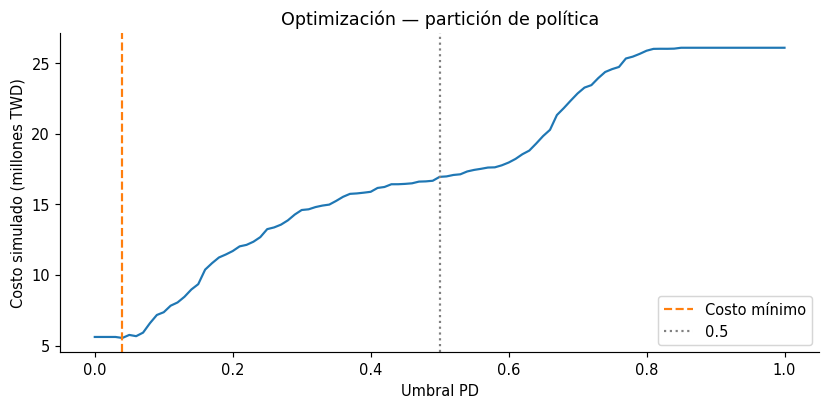

In [6]:
def exposure(df, ccf=CCF):
    limit=pd.to_numeric(df['LIMIT_BAL'],errors='raise').to_numpy(float)
    bill=pd.to_numeric(df['BILL_AMT1'],errors='raise').to_numpy(float)
    if not (np.isfinite(limit).all() and np.isfinite(bill).all() and (limit>0).all()):
        raise ValueError('EAD: revisar límites o saldos faltantes/no válidos')
    drawn=np.maximum(bill,0)
    return drawn+ccf*np.maximum(limit-drawn,0)
def threshold_table(y,p,ead,lgd=LGD,fp_cost=FP_COST):
    y=np.asarray(y); rows=[]
    for t in np.r_[0.,np.arange(.01,1,.01),1.]:
        pred=p>=t
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        cost=fp*fp_cost+np.sum(ead[(y==1)&(~pred)])*lgd
        rows.append(dict(threshold=float(t),cost_twd=float(cost),tn=tn,fp=fp,fn=fn,tp=tp,
            precision=precision_score(y,pred,zero_division=0),recall=recall_score(y,pred,zero_division=0),
            f1=f1_score(y,pred,zero_division=0),youden_j=tp/(tp+fn)+tn/(tn+fp)-1))
    return pd.DataFrame(rows)
p_policy=transform_pd(raw_pd(policy),method)
ead_policy=exposure(policy)
thresholds=threshold_table(policy[TARGET],p_policy,ead_policy)
# Desempate: umbral mayor para reducir alertas cuando el costo es idéntico.
optimal=thresholds.sort_values(['cost_twd','threshold'],ascending=[True,False]).iloc[0]
t=float(optimal.threshold)
display(pd.DataFrame([thresholds.iloc[(thresholds.threshold-.5).abs().argmin()],optimal,
    thresholds.loc[thresholds.f1.idxmax()],thresholds.loc[thresholds.youden_j.idxmax()]],
    index=['0.5','Costo mínimo','F1 máximo','Youden J máximo']))
print('Umbral congelado:',t)
fig,ax=plt.subplots(figsize=(8,4)); ax.plot(thresholds.threshold,thresholds.cost_twd/1e6)
ax.axvline(t,color='tab:orange',ls='--',label='Costo mínimo'); ax.axvline(.5,color='gray',ls=':',label='0.5')
ax.set(xlabel='Umbral PD',ylabel='Costo simulado (millones TWD)',title='Optimización — partición de política'); ax.legend(); fig.tight_layout()
fig.savefig(figures/'06_threshold_cost.png'); plt.show()

## 8. Congelar política y sensibilidad
El umbral binario marca clientes para gestión. Para tres acciones, usamos una regla ilustrativa: por debajo del umbral, seguimiento habitual; desde el umbral hasta un segundo corte fijo, revisión; por encima, revisión prioritaria/restricción simulada. No representa aprobación o rechazo automático de nuevos solicitantes: son clientes existentes. Las acciones no estiman contrafactuales. Los escenarios alternativos se calculan en desarrollo y no cambian el umbral base.

In [7]:
upper=max(.50,t+(1-t)*.5)
scenario_rows=[]
for lgd in [.25,.45,.65]:
    for fp_cost in [1000.,2000.,5000.]:
        tab=threshold_table(policy[TARGET],p_policy,ead_policy,lgd,fp_cost)
        best=tab.sort_values(['cost_twd','threshold'],ascending=[True,False]).iloc[0]
        scenario_rows.append({'lgd':lgd,'fp_cost_twd':fp_cost,'threshold':best.threshold,'cost_twd':best.cost_twd,'recall':best.recall})
scenarios=pd.DataFrame(scenario_rows); display(scenarios)
config={'method':method,'threshold':t,'priority_threshold':upper,'lgd':LGD,'ccf':CCF,'fp_cost_twd':FP_COST,
        'features':features,'target':TARGET,'seed':SEED,'best_params':search.best_params_,
        'cv_ap_fit':float(search.best_score_),'sklearn_version':sklearn.__version__,'xgboost_version':xgboost.__version__,
        'test_used_for_selection':False,'test_previously_observed':True,'pd_horizon':'next month','currency':'TWD'}
models.mkdir(exist_ok=True)
joblib.dump({'pipeline':base,'calibrator':{'raw':None,'platt':platt,'isotonic':iso}[method],'config':config},models/'optimized_xgboost.joblib')
(models/'optimization_metadata.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
print('Decisiones guardadas antes de cargar test.')

,lgd,fp_cost_twd,threshold,cost_twd,recall
0,0.25,1000.0,0.04,2.769000e+06,1.000000
1,0.25,2000.0,0.07,5.294637e+06,0.967337
2,0.25,5000.0,0.23,9.097572e+06,0.628141
3,0.45,1000.0,0.04,2.769000e+06,1.000000
4,0.45,2000.0,0.04,5.538000e+06,1.000000
5,0.45,5000.0,0.07,1.269435e+07,0.967337
6,0.65,1000.0,0.04,2.769000e+06,1.000000
7,0.65,2000.0,0.04,5.538000e+06,1.000000
8,0.65,5000.0,0.07,1.331405e+07,0.967337


Decisiones guardadas antes de cargar test.


## 9. Comparación retrospectiva en test
Ahora abrimos test por primera vez en este cuaderno. Comparamos original a 0.5, optimizado sin calibrar a 0.5, calibración seleccionada a 0.5 y política final. No modificar decisiones después de observar esta tabla. AP y AUC dependen del ranking, mientras recall y costos dependen del umbral. KS = max(TPR − FPR), Gini = 2 AUC − 1.

,threshold,roc_auc,ap,gini,ks,brier,log_loss,accuracy,precision,recall,f1,tn,fp,fn,tp,cost_twd
original_05,0.50,0.7806,0.5614,0.5612,0.4317,0.1344,0.4285,0.8202,0.6689,0.3700,0.4765,4430.0,243.0,836.0,491.0,2.972022e+07
tuned_raw_05,0.50,0.7803,0.5588,0.5607,0.4290,0.1348,0.4290,0.8182,0.6639,0.3602,0.4670,4431.0,242.0,849.0,478.0,2.997768e+07
selected_calibration_05,0.50,0.7803,0.5588,0.5607,0.4290,0.1348,0.4290,0.8182,0.6639,0.3602,0.4670,4431.0,242.0,849.0,478.0,2.997768e+07
final_policy,0.04,0.7803,0.5588,0.5607,0.4290,0.1348,0.4290,0.2280,0.2226,0.9992,0.3641,42.0,4631.0,1.0,1326.0,9.343708e+06


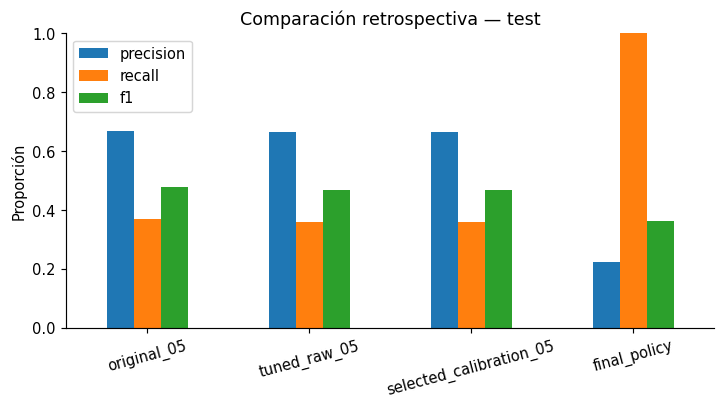

In [8]:
test=load_frame(processed/'credit_risk_test_features.csv')
assert set(test.index).isdisjoint(train.index)
original=joblib.load(models/'best_model.joblib')
assert type(original.named_steps['model']).__name__=='XGBClassifier'
assert list(original.feature_names_in_)==features and list(original.classes_)==[0,1]
y=test[TARGET].to_numpy(); ead=exposure(test)
p_original=original.predict_proba(X_of(test))[:,1]
p_raw=raw_pd(test); p_final=transform_pd(p_raw,method)
def evaluate(p,threshold):
    pred=p>=threshold
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    fpr,tpr,_=roc_curve(y,p); auc=roc_auc_score(y,p)
    return {'threshold':threshold,'roc_auc':auc,'ap':average_precision_score(y,p),'gini':2*auc-1,
            'ks':float(np.max(tpr-fpr)),'brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
            'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred),'f1':f1_score(y,pred,zero_division=0),
            'tn':tn,'fp':fp,'fn':fn,'tp':tp,'cost_twd':fp*FP_COST+LGD*ead[(y==1)&(~pred)].sum()}
comparison=pd.DataFrame({k:evaluate(p,h) for k,p,h in [('original_05',p_original,.5),('tuned_raw_05',p_raw,.5),
    ('selected_calibration_05',p_final,.5),('final_policy',p_final,t)]}).T
display(comparison.round(4))
fig,ax=plt.subplots(figsize=(7,4)); comparison[['precision','recall','f1']].plot.bar(ax=ax,rot=15)
ax.set(ylabel='Proporción',ylim=(0,1),title='Comparación retrospectiva — test'); fig.tight_layout()
fig.savefig(figures/'06_test_comparison.png'); plt.show()

## 10. Pérdida esperada y política simulada
Agrupamos EL por acciones, sin interpretarla como pérdida evitada. La suma es la exposición esperada bajo las probabilidades y supuestos del escenario, no una previsión validada de pérdida monetaria. Reportamos tasa observada solo para evaluación retrospectiva.

,clientes,default_observado,pd_media,ead_twd,el_twd,share
action,,,,,,
Restricción simulada / prioridad,685,0.6745,0.6773,52153496.9,1.599992e+07,0.1142
Revisión,5272,0.1639,0.1622,462314561.4,2.805841e+07,0.8787
Seguimiento habitual,43,0.0233,0.0379,6792745.5,1.156762e+05,0.0072


EL total TWD: 44174003.67


,LGD,CCF,EL_TWD
0,0.25,0.1,1.913200e+07
1,0.25,0.3,2.454111e+07
2,0.25,0.6,3.265478e+07
3,0.45,0.1,3.443761e+07
4,0.45,0.3,4.417400e+07
5,0.45,0.6,5.877860e+07
6,0.65,0.1,4.974321e+07
7,0.65,0.3,6.380689e+07
8,0.65,0.6,8.490242e+07


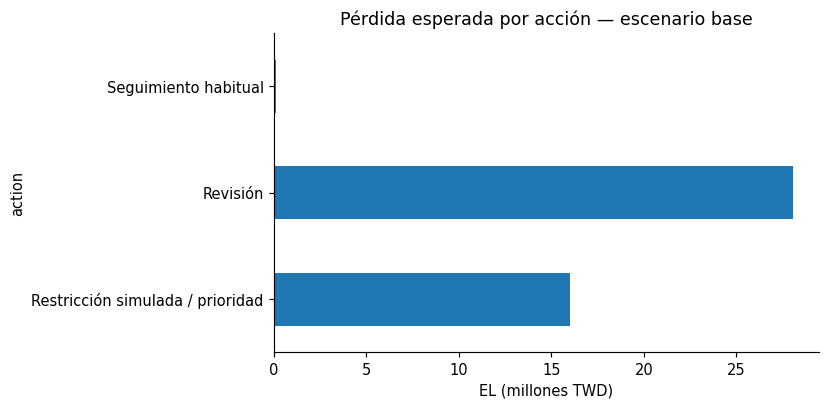

In [9]:
action=np.select([p_final>=upper,p_final>=t],['Restricción simulada / prioridad','Revisión'],default='Seguimiento habitual')
scores=pd.DataFrame({'row_id':test.index,'DEFAULT':y,'PD':p_final,'EAD_TWD':ead,'LGD':LGD,
    'EL_TWD':p_final*LGD*ead,'flag':(p_final>=t).astype(int),'action':action})
assert scores.PD.between(0,1).all() and (scores.EL_TWD>=0).all()
policy_summary=scores.groupby('action').agg(clientes=('DEFAULT','size'),default_observado=('DEFAULT','mean'),
    pd_media=('PD','mean'),ead_twd=('EAD_TWD','sum'),el_twd=('EL_TWD','sum'))
policy_summary['share']=policy_summary.clientes/len(scores)
assert policy_summary.clientes.sum()==len(test)
display(policy_summary.round(4))
print('EL total TWD:',round(scores.EL_TWD.sum(),2))
financial_sensitivity=pd.DataFrame([{'LGD':l,'CCF':cc,'EL_TWD':float((p_final*l*exposure(test,cc)).sum())}
    for l in [.25,.45,.65] for cc in [.1,.3,.6]])
display(financial_sensitivity)
fig,ax=plt.subplots(figsize=(8,4)); policy_summary.el_twd.div(1e6).plot.barh(ax=ax)
ax.set(xlabel='EL (millones TWD)',title='Pérdida esperada por acción — escenario base'); fig.tight_layout()
fig.savefig(figures/'06_expected_loss.png'); plt.show()

## 11. Exportación y controles
El artefacto original no se sobrescribe. El modelo optimizado incluye pipeline, calibrador y configuración. Para inferencia futura: predict_proba del pipeline, aplicar calibrador según method (logits para Platt), recortar a [1e-6, 1−1e-6] y comparar con threshold. Guardar versiones y usar el mismo entorno.

In [10]:
for name,table in [('tuning_cv',results),('calibration_selection',calibration_results),('threshold_cost',thresholds),
    ('cost_scenarios',scenarios),('test_comparison',comparison),('policy_summary',policy_summary),
    ('financial_sensitivity',financial_sensitivity),('test_scores',scores)]:
    table.to_csv(processed/f'06_{name}.csv',index=name in ['test_comparison','policy_summary'])
loaded=joblib.load(models/'optimized_xgboost.joblib')
p=loaded['pipeline'].predict_proba(X_of(test.head(10)))[:,1]
k=loaded['config']['method']; calibrator=loaded['calibrator']
if k=='platt': p=calibrator.predict_proba(logits(p))[:,1]
elif k=='isotonic': p=calibrator.predict(p)
np.testing.assert_allclose(np.clip(p,1e-6,1-1e-6),p_final[:10])
print('Artefacto recargado y comprobado. Resultados:',processed)
print('Recall original/final:',comparison.loc['original_05','recall'],comparison.loc['final_policy','recall'])

Artefacto recargado y comprobado. Resultados: C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\data\processed
Recall original/final: 0.3700075357950264 0.9992464204973625
